In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [33]:
combine_tracking = pd.read_csv("data/combine_tracking.csv")
combine_results = pd.read_csv("data/combine_results.csv")

# Player Isolation

We are viewing offensive linemen, so we will first get a look at all of our linemen provided to us in the data set

In [2]:
oline = combine_tracking[combine_tracking['drill_type'] == 'SKILL_DRILLS_OL']

In [7]:
oline['nfl_id'].unique()

array([58286, 58896, 58261, 58454, 58259, 58866, 58300, 58226, 58994,
       58231, 58416, 58211, 58209, 58359, 58242, 58296, 58898, 58253,
       58220, 58940, 58852, 58423, 58958, 58332, 58294, 58373, 58214,
       58206, 58346, 58396, 58303, 58376, 58476, 58987, 58455, 58358,
       58262, 58946, 57184, 57863, 57444, 57299, 57428, 57628, 57283,
       57581, 57376, 57240, 57262, 57194, 57135, 57238, 57183, 57297,
       57330, 57189, 57150, 57353, 57357, 57293, 57599, 57224, 57126,
       57687, 57141, 57854, 57207, 57335, 57172, 57176, 57408, 57654,
       57202, 57284, 57180, 57337, 57374, 57796, 57128, 57198, 57406,
       57165, 57368, 57310, 55891, 56183, 56034, 55924, 56066, 55901,
       56344, 55962, 55983, 56518, 55922, 56636, 55870, 56645, 55987,
       55903, 55913, 56095, 56103, 55973, 55878, 56572, 55971, 55930,
       55927, 56451, 56055, 55982, 55875, 56203, 55874, 56021, 56450,
       55968, 55976, 56090, 56625])

For this example we are going to focus on Darnell Wright and Paris Johnson Jr. These were the first two offensive linemen taken in the 2023 draft.

Their `nfl_id`'s are:
- 55874
- 55870

In [168]:
wright = oline[oline['nfl_id'] == 55874]
paris = oline[oline['nfl_id'] == 55870]

In [180]:
print(wright.groupby(['drill_name', 'attempt']).size().reset_index(name='count'))
print(paris.groupby(['drill_name', 'attempt']).size().reset_index(name='count'))

                               drill_name  attempt  count
0  FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE        1    142
1      OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT        1     55
2          OL_PULL_DRILL_FOLD_BLOCK_RIGHT        1     37
3           OL_PULL_DRILL_LONG_PULL_RIGHT        1     51
4                   PASS_PRO_MIRROR_DRILL        1    161
5                          PASS_RUSH_DROP        1     42
6                          PASS_RUSH_DROP        2     44
7                            SCREEN_DRILL        1     65
                               drill_name  attempt  count
0  FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE        1    165
1      OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT        1     51
2          OL_PULL_DRILL_FOLD_BLOCK_RIGHT        1     44
3           OL_PULL_DRILL_LONG_PULL_RIGHT        1     54
4                   PASS_PRO_MIRROR_DRILL        1     75
5                          PASS_RUSH_DROP        1     49
6                          PASS_RUSH_DROP        2     47
7             

In [170]:
wright_weight = combine_results.loc[
    combine_results['nfl_id'] == 55874,
    'combine_weight'
].iloc[0]

paris_weight = combine_results.loc[
    combine_results['nfl_id'] == 55870,
    'combine_weight'
].iloc[0]

In [171]:
wright['force'] = (
    wright['a'] * (wright_weight / 2.20462)
).round(2)

paris['force'] = (
    paris['a'] * (paris_weight / 2.20462)
).round(2)

# Isolating the Pass Protection Drill

Our first drill we wish to focus on is the Pass Protection Mirror Drill

This drill is a drill simulating pass protection concepts

Using acceleration and the weight of the players, we can calculate a Force statistic that measures the force the player is exerting at every tenth of a second during the drill, in Newtons

In [153]:
pass_pro_wright = wright.loc[
    (wright['drill_name'] == 'PASS_PRO_MIRROR_DRILL') &
    (wright['attempt'] == 1),
    ['x', 'y', 'a', 'time', 'force']
].rename(columns = {'a': 'acceleration'})

# Convert time to datetime
pass_pro_wright['time'] = pd.to_datetime(pass_pro_wright['time'])

# Calculate elapsed time
pass_pro_wright['time'] = (
    pass_pro_wright['time'] - pass_pro_wright['time'].min()
).dt.total_seconds()

In [173]:
pass_pro_paris = paris.loc[
    (paris['drill_name'] == 'PASS_PRO_MIRROR_DRILL') &
    (paris['attempt'] == 1),
    ['x', 'y', 'a', 'time', 'force']
].rename(columns = {'a': 'acceleration'})

# Convert time to datetime
pass_pro_paris['time'] = pd.to_datetime(pass_pro_paris['time'])

# Calculate elapsed time
pass_pro_paris['time'] = (
    pass_pro_paris['time'] - pass_pro_paris['time'].min()
).dt.total_seconds()

## Darnell Wright Force (N) over Time

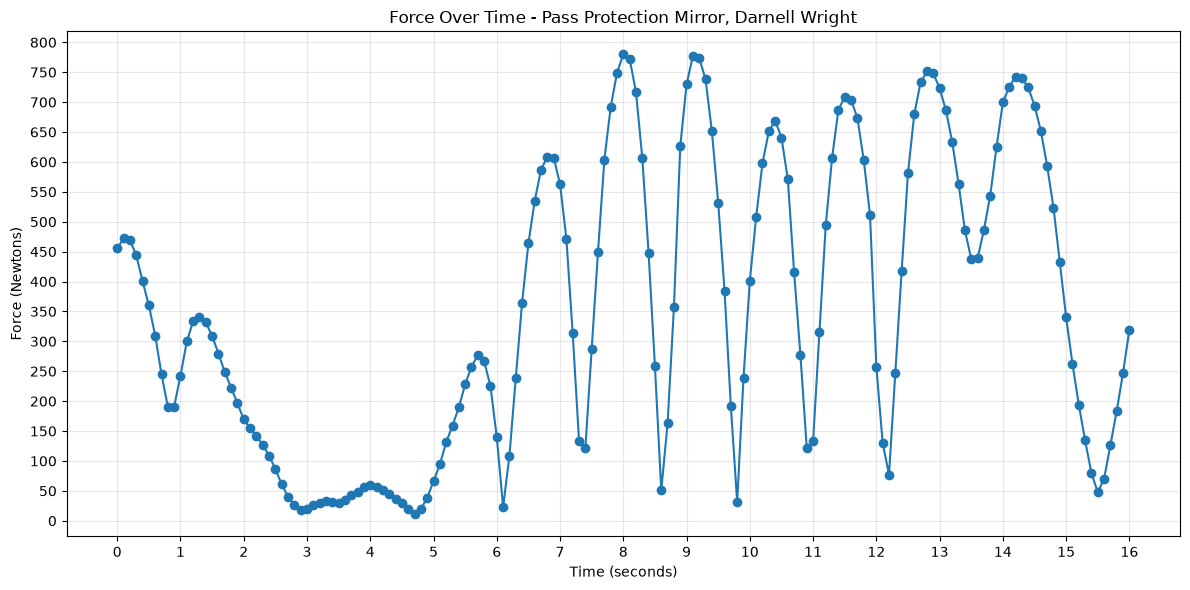

In [158]:
plt.figure(figsize=(12, 6))

plt.plot(
    pass_pro_wright['time'],
    pass_pro_wright['force'],
    marker='o',
    linestyle='-'
)

plt.xlabel('Time (seconds)')
plt.ylabel('Force (Newtons)')
plt.title('Force Over Time - Pass Protection Mirror, Darnell Wright')

plt.yticks(range(0, 801, 50))
plt.xticks(np.arange(0, 16.1, 1))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

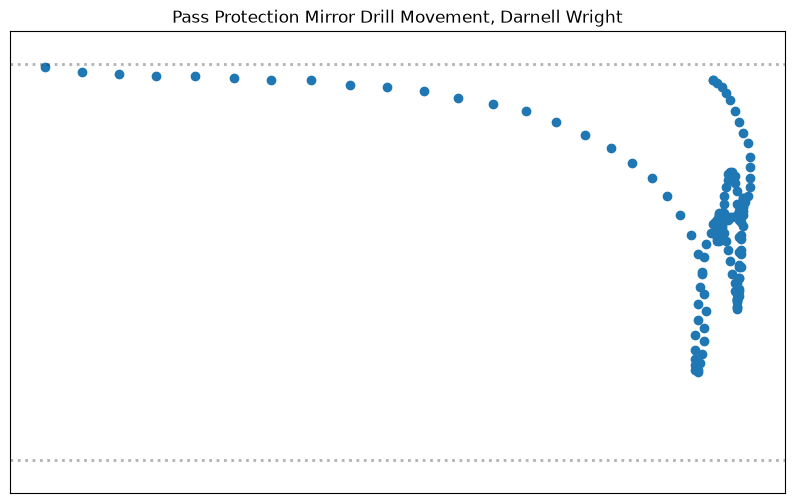

In [194]:
plt.figure(figsize=(10, 6))
plt.scatter(pass_pro_wright['x'], pass_pro_wright['y'])

plt.axhline(y = 23.61, color = 'black', linestyle = ':', linewidth = 2, alpha = 0.3)
plt.axhline(y = 29.69, color = 'black', linestyle = ':', linewidth = 2, alpha = 0.3)

plt.xticks([])
plt.yticks([])

plt.title('Pass Protection Mirror Drill Movement, Darnell Wright')

plt.axis('equal')
plt.gca().invert_xaxis()
plt.show()

## Paris Johnson Jr. Force (N) over Time

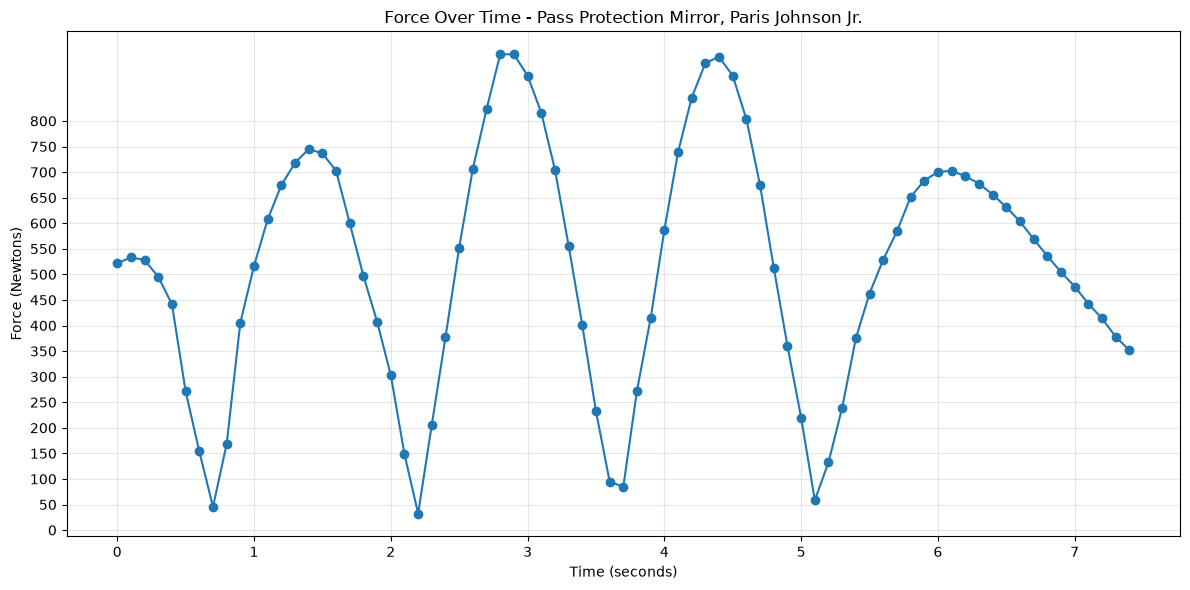

In [177]:
plt.figure(figsize=(12, 6))

plt.plot(
    pass_pro_paris['time'],
    pass_pro_paris['force'],
    marker='o',
    linestyle='-'
)

plt.xlabel('Time (seconds)')
plt.ylabel('Force (Newtons)')
plt.title('Force Over Time - Pass Protection Mirror, Paris Johnson Jr.')

plt.yticks(range(0, 801, 50))
plt.xticks(np.arange(0, 7.5, 1))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

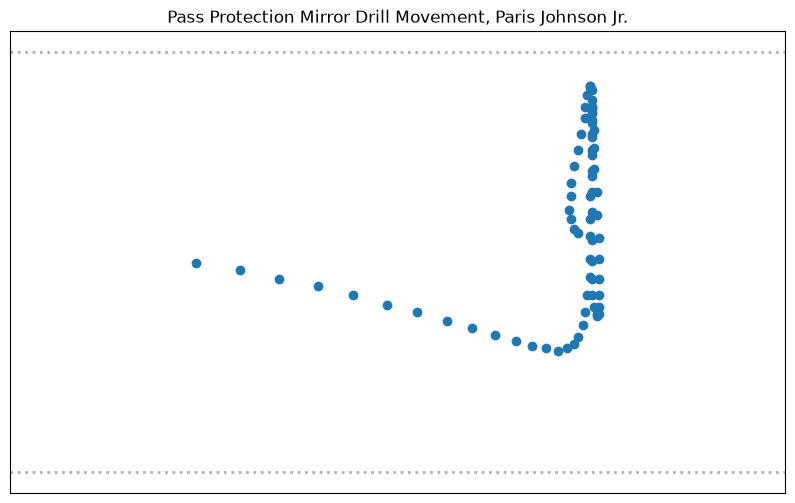

In [178]:
plt.figure(figsize=(10, 6))
plt.scatter(pass_pro_paris['x'], pass_pro_paris['y'])

plt.axhline(y = 23.61, color = 'black', linestyle = ':', linewidth = 2, alpha = 0.3)
plt.axhline(y = 29.69, color = 'black', linestyle = ':', linewidth = 2, alpha = 0.3)

plt.xticks([])
plt.yticks([])

plt.title('Pass Protection Mirror Drill Movement, Paris Johnson Jr.')

plt.axis('equal')
plt.gca().invert_xaxis()
plt.show()

# Isolating the Wave Drill 

In [181]:
wave_wright = wright.loc[
    (wright['drill_name'] == 'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE') &
    (wright['attempt'] == 1),
    ['x', 'y', 'a', 'time', 'force']
].rename(columns = {'a': 'acceleration'})

# Convert time to datetime
wave_wright['time'] = pd.to_datetime(wave_wright['time'])

# Calculate elapsed time
wave_wright['time'] = (
    wave_wright['time'] - wave_wright['time'].min()
).dt.total_seconds()

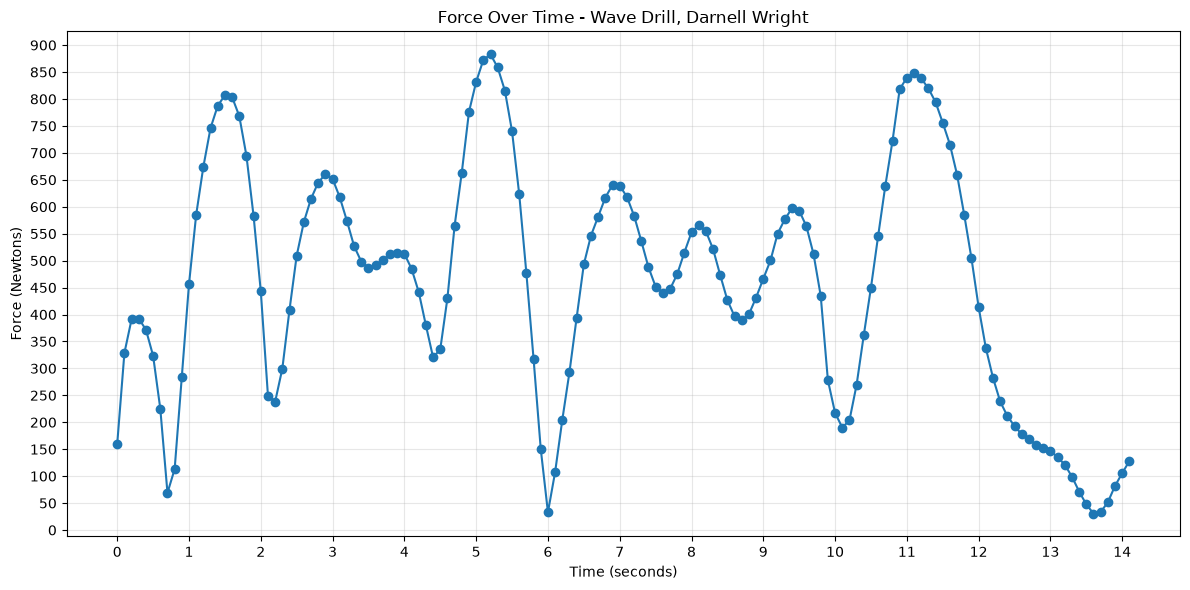

In [189]:
plt.figure(figsize=(12, 6))

plt.plot(
    wave_wright['time'],
    wave_wright['force'],
    marker='o',
    linestyle='-'
)

plt.xlabel('Time (seconds)')
plt.ylabel('Force (Newtons)')
plt.title('Force Over Time - Wave Drill, Darnell Wright')

plt.yticks(range(0, 901, 50))
plt.xticks(np.arange(0, 14.1, 1))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

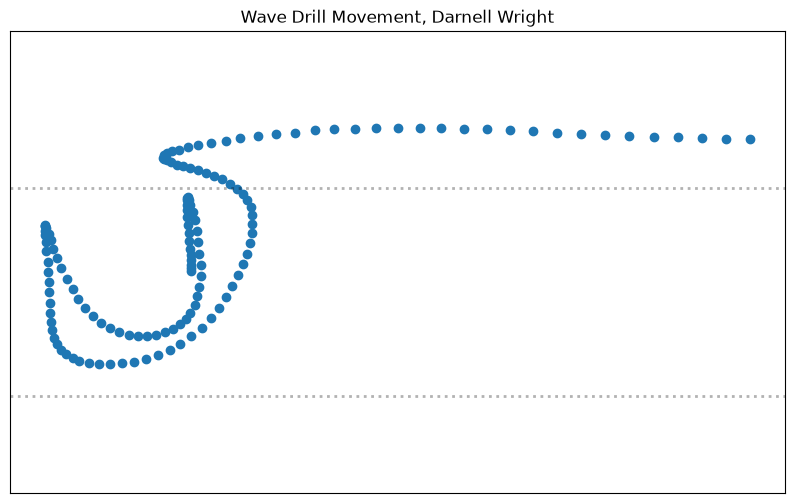

In [195]:
plt.figure(figsize=(10, 6))
plt.scatter(wave_wright['x'], wave_wright['y'])

plt.axhline(y = 23.61, color = 'black', linestyle = ':', linewidth = 2, alpha = 0.3)
plt.axhline(y = 29.69, color = 'black', linestyle = ':', linewidth = 2, alpha = 0.3)

plt.xticks([])
plt.yticks([])

plt.title('Wave Drill Movement, Darnell Wright')

plt.axis('equal')
plt.gca().invert_xaxis()
plt.show()

In [183]:
wave_paris = paris.loc[
    (paris['drill_name'] == 'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE') &
    (paris['attempt'] == 1),
    ['x', 'y', 'a', 'time', 'force']
].rename(columns = {'a': 'acceleration'})

# Convert time to datetime
wave_paris['time'] = pd.to_datetime(wave_paris['time'])

# Calculate elapsed time
wave_paris['time'] = (
    wave_paris['time'] - wave_paris['time'].min()
).dt.total_seconds()

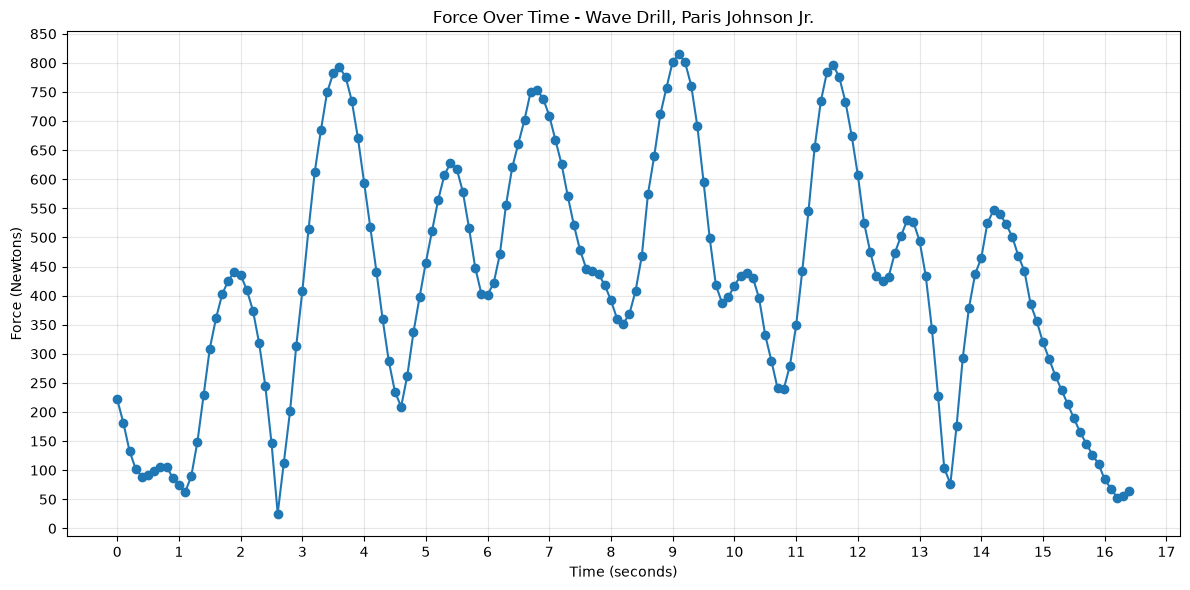

In [193]:
plt.figure(figsize=(12, 6))

plt.plot(
    wave_paris['time'],
    wave_paris['force'],
    marker='o',
    linestyle='-'
)

plt.xlabel('Time (seconds)')
plt.ylabel('Force (Newtons)')
plt.title('Force Over Time - Wave Drill, Paris Johnson Jr.')

plt.yticks(range(0, 851, 50))
plt.xticks(np.arange(0, 17.1, 1))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

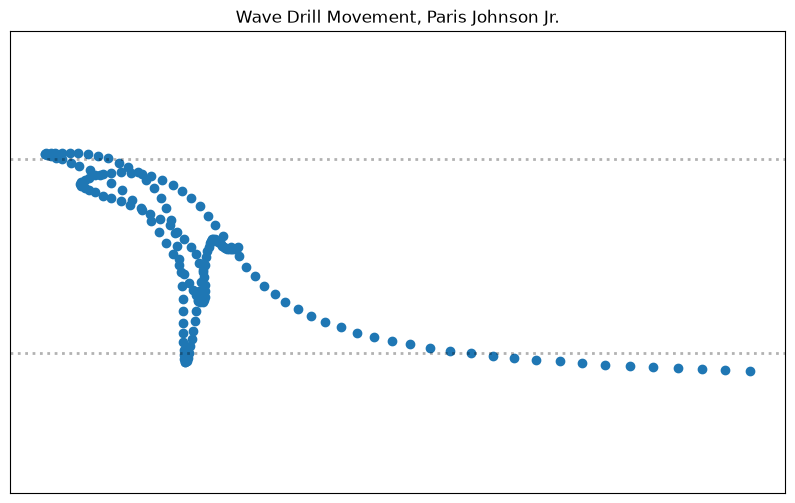

In [196]:
plt.figure(figsize=(10, 6))
plt.scatter(wave_paris['x'], wave_paris['y'])

plt.axhline(y = 23.61, color = 'black', linestyle = ':', linewidth = 2, alpha = 0.3)
plt.axhline(y = 29.69, color = 'black', linestyle = ':', linewidth = 2, alpha = 0.3)

plt.xticks([])
plt.yticks([])

plt.title('Wave Drill Movement, Paris Johnson Jr.')

plt.axis('equal')
plt.gca().invert_xaxis()
plt.show()